# Escalado al dataset completo: CNN-1D (2 canales, V1)

In [1]:
import os
import json
import glob
import numpy as np
import pandas as pd
import mne
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve,
)

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

mne.set_log_level("WARNING")

TFM_DIR = os.path.expanduser("~/Desktop/TFM")
DATA_DIR = os.path.expanduser("~/Desktop/TFM/datos_completos")
IMAGES_DIR = os.path.join(TFM_DIR, "images")
os.makedirs(IMAGES_DIR, exist_ok=True)

CHANNELS = ["EEG Fpz-Cz", "EEG Pz-Oz"]
EPOCH_DURATION = 30.0

print("Buscando datos en:", DATA_DIR)

Buscando datos en: C:\Users\alber/Desktop/TFM/datos_completos


## 1. Localizar todos los pares PSG/Hypnogram descargados

In [2]:
def find_psg_hypnogram_pairs(data_dir):
    psg_files = sorted(glob.glob(os.path.join(data_dir, "**", "*-PSG.edf"), recursive=True))
    pairs = []
    for psg in psg_files:
        base = os.path.basename(psg)
        prefix = base[:6]  # ej: "SC4001"
        candidates = glob.glob(os.path.join(os.path.dirname(psg), prefix + "*-Hypnogram.edf"))
        if candidates:
            pairs.append((psg, candidates[0]))
        else:
            print(f"[AVISO] No se encontró Hypnogram para: {base}")
    return pairs

pairs = find_psg_hypnogram_pairs(DATA_DIR)
print(f"Pares PSG/Hypnogram encontrados: {len(pairs)}")
print("(deberían ser 153)")

Pares PSG/Hypnogram encontrados: 153
(deberían ser 153)


## 2. Funciones de carga y segmentación

In [3]:
ANNOTATION_TO_LABEL = {
    "Sleep stage W": 0,
    "Sleep stage 1": 1,
    "Sleep stage 2": 1,
    "Sleep stage 3": 1,
    "Sleep stage 4": 1,
    "Sleep stage R": 1,
}

def load_subject(psg_path, hyp_path):
    raw = mne.io.read_raw_edf(psg_path, preload=True)
    annot = mne.read_annotations(hyp_path)
    raw.set_annotations(annot, emit_warning=False)

    sleep_onset = [a["onset"] for a in annot if a["description"] != "Sleep stage W"]
    if sleep_onset:
        start = max(raw.times[0], min(sleep_onset) - 30 * 60)
        end = min(raw.times[-1], max(sleep_onset) + 30 * 60)
        raw.crop(tmin=start, tmax=end)

    return raw

def raw_to_epochs_labels(raw, channels):
    events, event_id = mne.events_from_annotations(raw, chunk_duration=EPOCH_DURATION)
    valid_desc = {k: v for k, v in event_id.items() if k in ANNOTATION_TO_LABEL}
    if not valid_desc:
        return None, None

    epochs = mne.Epochs(
        raw, events, event_id=valid_desc,
        tmin=0, tmax=EPOCH_DURATION - 1.0 / raw.info["sfreq"],
        baseline=None, preload=True, picks=channels
    )
    X = epochs.get_data()
    inv_id = {v: k for k, v in valid_desc.items()}
    y = np.array([ANNOTATION_TO_LABEL[inv_id[e]] for e in epochs.events[:, 2]])
    return X, y

## 3. Procesar los 153 registros

In [4]:
ALL_X, ALL_y, ALL_subjects = [], [], []

for idx, (psg_path, hyp_path) in enumerate(pairs):
    fname = os.path.basename(psg_path)
    subject_id = int(fname[3:5])  # ej: "SC4001E0" -> sujeto 00

    print(f"[{idx + 1}/{len(pairs)}] Procesando {fname} (sujeto {subject_id})...")

    try:
        raw = load_subject(psg_path, hyp_path)
        raw.filter(l_freq=0.5, h_freq=30.0, picks=CHANNELS)

        X, y = raw_to_epochs_labels(raw, channels=CHANNELS)
        if X is None:
            print(f"  [AVISO] Sin épocas válidas, se omite.")
            continue

        ALL_X.append(X)
        ALL_y.append(y)
        ALL_subjects.append(np.full(len(y), subject_id))

    except Exception as e:
        print(f"  [ERROR] Fallo procesando {fname}: {e}")

X = np.concatenate(ALL_X, axis=0).astype(np.float32)
y = np.concatenate(ALL_y, axis=0)
subjects = np.concatenate(ALL_subjects, axis=0)

print("\nForma final de X:", X.shape)
print("Forma final de y:", y.shape)
print("Nº de sujetos distintos:", len(set(subjects)))
print("Distribución de clases -> vigilia (0):", (y == 0).sum(), "| sueño (1):", (y == 1).sum())

[1/153] Procesando SC4001E0-PSG.edf (sujeto 0)...


C:\Users\alber\AppData\Local\Temp\ipykernel_10052\3207632483.py:11: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(psg_path, preload=True)
C:\Users\alber\AppData\Local\Temp\ipykernel_10052\3207632483.py:11: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(psg_path, preload=True)
C:\Users\alber\AppData\Local\Temp\ipykernel_10052\3207632483.py:11: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(psg_path, preload=True)


[2/153] Procesando SC4002E0-PSG.edf (sujeto 0)...


C:\Users\alber\AppData\Local\Temp\ipykernel_10052\3207632483.py:11: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(psg_path, preload=True)
C:\Users\alber\AppData\Local\Temp\ipykernel_10052\3207632483.py:11: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(psg_path, preload=True)
C:\Users\alber\AppData\Local\Temp\ipykernel_10052\3207632483.py:11: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(psg_path, preload=True)


[3/153] Procesando SC4011E0-PSG.edf (sujeto 1)...


...

[152/153] Procesando SC4821G0-PSG.edf (sujeto 82)...


C:\Users\alber\AppData\Local\Temp\ipykernel_10052\3207632483.py:11: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(psg_path, preload=True)
C:\Users\alber\AppData\Local\Temp\ipykernel_10052\3207632483.py:11: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(psg_path, preload=True)
C:\Users\alber\AppData\Local\Temp\ipykernel_10052\3207632483.py:11: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(psg_path, preload=True)


[153/153] Procesando SC4822G0-PSG.edf (sujeto 82)...


C:\Users\alber\AppData\Local\Temp\ipykernel_10052\3207632483.py:11: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(psg_path, preload=True)
C:\Users\alber\AppData\Local\Temp\ipykernel_10052\3207632483.py:11: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(psg_path, preload=True)
C:\Users\alber\AppData\Local\Temp\ipykernel_10052\3207632483.py:11: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(psg_path, preload=True)



Forma final de X: (296043, 2, 3000)
Forma final de y: (296043,)
Nº de sujetos distintos: 78
Distribución de clases -> vigilia (0): 166515 | sueño (1): 129528


## 4. División train/val/test por sujeto (70/15/15)

In [5]:
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
train_idx, temp_idx = next(gss1.split(X, y, groups=subjects))

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
val_idx, test_idx = next(gss2.split(X[temp_idx], y[temp_idx], groups=subjects[temp_idx]))
val_idx, test_idx = temp_idx[val_idx], temp_idx[test_idx]

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

print("Train:", X_train.shape, "| Val:", X_val.shape, "| Test:", X_test.shape)
print("Sujetos en train:", len(set(subjects[train_idx])))
print("Sujetos en val:  ", len(set(subjects[val_idx])))
print("Sujetos en test: ", len(set(subjects[test_idx])))

Train: (205045, 2, 3000) | Val: (46265, 2, 3000) | Test: (44733, 2, 3000)
Sujetos en train: 54
Sujetos en val:   12
Sujetos en test:  12


In [6]:
import json

split_ids = {
    "train": sorted(str(s) for s in set(subjects[train_idx])),
    "val":   sorted(str(s) for s in set(subjects[val_idx])),
    "test":  sorted(str(s) for s in set(subjects[test_idx])),
}
with open(os.path.join(TFM_DIR, "sujetos_por_particion.json"), "w") as f:
    json.dump(split_ids, f, indent=2)

print({k: len(v) for k, v in split_ids.items()})
print("Test:", split_ids["test"])

{'train': 54, 'val': 12, 'test': 12}
Test: ['0', '12', '30', '31', '34', '35', '4', '40', '5', '54', '59', '70']


## 5. Normalización y guardado

In [6]:
mean_train = X_train.mean(dtype=np.float32)
std_train = X_train.std(dtype=np.float32)

X_train_norm = ((X_train - mean_train) / std_train).astype(np.float32)
X_val_norm = ((X_val - mean_train) / std_train).astype(np.float32)
X_test_norm = ((X_test - mean_train) / std_train).astype(np.float32)

X_train_norm = np.transpose(X_train_norm, (0, 2, 1))
X_val_norm = np.transpose(X_val_norm, (0, 2, 1))
X_test_norm = np.transpose(X_test_norm, (0, 2, 1))

print("Forma de entrada al modelo:", X_train_norm.shape)

np.savez(os.path.join(TFM_DIR, "datos_procesados_completo_2canales.npz"),
         X_train_norm=X_train_norm, y_train=y_train,
         X_val_norm=X_val_norm, y_val=y_val,
         X_test_norm=X_test_norm, y_test=y_test)

print("Guardado correctamente.")

Forma de entrada al modelo: (205045, 3000, 2)
Guardado correctamente.


In [1]:
import os
import numpy as np

TFM_DIR = os.path.expanduser("~/Desktop/TFM")
data = np.load(os.path.join(TFM_DIR, "datos_procesados_completo_2canales.npz"))

X_train_norm = data["X_train_norm"]
y_train = data["y_train"]
X_val_norm = data["X_val_norm"]
y_val = data["y_val"]
X_test_norm = data["X_test_norm"]
y_test = data["y_test"]

print("Train:", X_train_norm.shape, "| Val:", X_val_norm.shape, "| Test:", X_test_norm.shape)

Train: (205045, 3000, 2) | Val: (46265, 3000, 2) | Test: (44733, 3000, 2)


## 6. Modelo: CNN-1D 

In [3]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

def build_cnn1d(input_shape):
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv1D(32, kernel_size=7, activation="relu", padding="same"),
        layers.MaxPooling1D(4),
        layers.Conv1D(64, kernel_size=7, activation="relu", padding="same"),
        layers.MaxPooling1D(4),
        layers.Conv1D(128, kernel_size=5, activation="relu", padding="same"),
        layers.GlobalAveragePooling1D(),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

model = build_cnn1d(X_train_norm.shape[1:])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 3000, 32)       │           480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 750, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 750, 64)        │        14,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 187, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 187, 128)       │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 64,289 (251.13 KB)

 Trainable params: 64,289 (251.13 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Entrenamiento — Configuración V1 (30 épocas, patience 5)

In [4]:
early_stop = callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)

history = model.fit(
    X_train_norm, y_train,
    validation_data=(X_val_norm, y_val),
    epochs=30,
    batch_size=64,
    class_weight={0: 1.0, 1: (y_train == 0).sum() / max((y_train == 1).sum(), 1)},
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/30
3204/3204 ━━━━━━━━━━━━━━━━━━━━ 137s 42ms/step - accuracy: 0.9533 - loss: 0.1361 - val_accuracy: 0.9657 - val_loss: 0.0869
Epoch 2/30
3204/3204 ━━━━━━━━━━━━━━━━━━━━ 125s 39ms/step - accuracy: 0.9658 - loss: 0.0979 - val_accuracy: 0.9663 - val_loss: 0.0892
Epoch 3/30
3204/3204 ━━━━━━━━━━━━━━━━━━━━ 125s 39ms/step - accuracy: 0.9683 - loss: 0.0906 - val_accuracy: 0.9672 - val_loss: 0.0857
Epoch 4/30
3204/3204 ━━━━━━━━━━━━━━━━━━━━ 125s 39ms/step - accuracy: 0.9701 - loss: 0.0863 - val_accuracy: 0.9624 - val_loss: 0.0925
Epoch 5/30
3204/3204 ━━━━━━━━━━━━━━━━━━━━ 135s 42ms/step - accuracy: 0.9712 - loss: 0.0831 - val_accuracy: 0.9624 - val_loss: 0.0990
Epoch 6/30
3204/3204 ━━━━━━━━━━━━━━━━━━━━ 129s 40ms/step - accuracy: 0.9726 - loss: 0.0791 - val_accuracy: 0.9628 - val_loss: 0.0981
Epoch 7/30
3204/3204 ━━━━━━━━━━━━━━━━━━━━ 129s 40ms/step - accuracy: 0.9733 - loss: 0.0769 - val_accuracy: 0.9638 - val_loss: 0.0937
Epoch 8/30
3204/3204 ━━━━━━━━━━━━━━━━━━━━ 127s 40ms/step - accuracy: 

In [5]:
model.save(os.path.join(TFM_DIR, "modelo_final_cnn1d_completo_v1.keras"))

with open(os.path.join(TFM_DIR, "historial_cnn1d_completo_v1.json"), "w") as f:
    json.dump(history.history, f)

n_epochs_trained = len(history.history["loss"])
best_epoch = int(np.argmin(history.history["val_loss"])) + 1
best_val_loss = min(history.history["val_loss"])

print(f"Modelo e historial guardados. Épocas entrenadas: {n_epochs_trained}")
print(f"Mejor época: {best_epoch} (val_loss = {best_val_loss:.4f})")

Modelo e historial guardados. Épocas entrenadas: 8
Mejor época: 3 (val_loss = 0.0857)


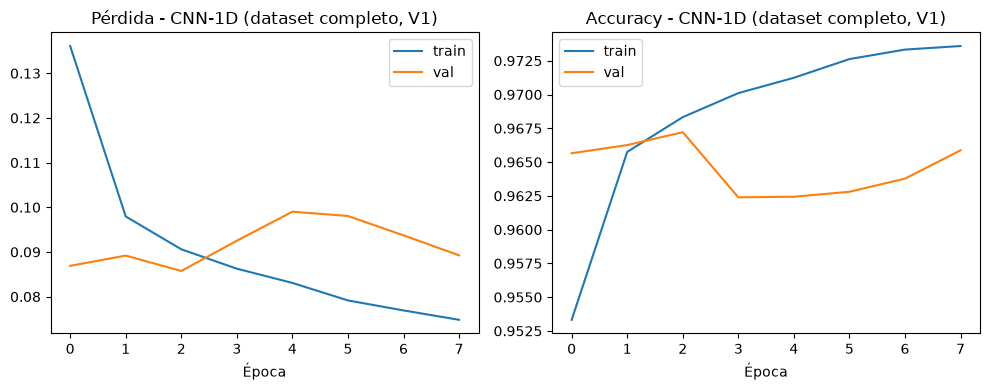

In [8]:
import matplotlib.pyplot as plt
IMAGES_DIR = os.path.join(TFM_DIR, "images")
os.makedirs(IMAGES_DIR, exist_ok=True)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="val")
plt.title("Pérdida - CNN-1D (dataset completo, V1)")
plt.xlabel("Época")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="val")
plt.title("Accuracy - CNN-1D (dataset completo, V1)")
plt.xlabel("Época")
plt.legend()

plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, "curvas_entrenamiento_completo_cnn1d.png"),
            dpi=150, bbox_inches="tight")
plt.show()

## 8. Evaluación en el conjunto de test

1398/1398 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step
              precision    recall  f1-score   support

     Vigilia      0.986     0.950     0.968     25152
       Sueño      0.938     0.983     0.960     19581

    accuracy                          0.964     44733
   macro avg      0.962     0.966     0.964     44733
weighted avg      0.965     0.964     0.964     44733

ROC-AUC: 0.995


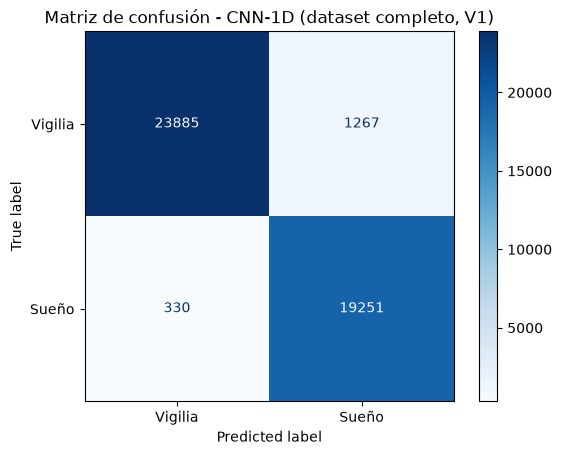

In [10]:
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve,
)


y_pred_prob = model.predict(X_test_norm).ravel()
y_pred = (y_pred_prob >= 0.5).astype(int)

print(classification_report(y_test, y_pred, target_names=["Vigilia", "Sueño"], digits=3))

roc_auc = roc_auc_score(y_test, y_pred_prob)
print(f"ROC-AUC: {roc_auc:.3f}")

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Vigilia", "Sueño"])
disp.plot(cmap="Blues")
plt.title("Matriz de confusión - CNN-1D (dataset completo, V1)")
plt.savefig(os.path.join(IMAGES_DIR, "matriz_confusion_completo_cnn1d.png"),
            dpi=150, bbox_inches="tight")
plt.show()

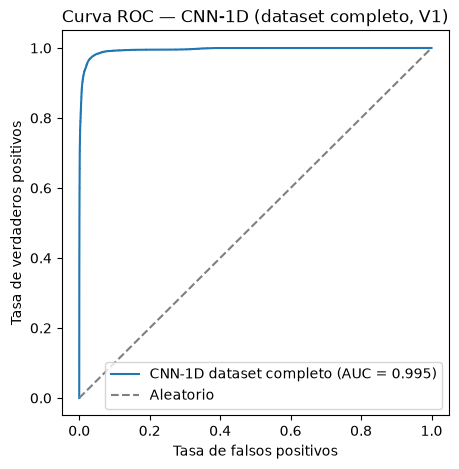

In [11]:
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"CNN-1D dataset completo (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Aleatorio")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curva ROC — CNN-1D (dataset completo, V1)")
plt.legend()
plt.savefig(os.path.join(IMAGES_DIR, "roc_curve_completo_cnn1d.png"),
            dpi=150, bbox_inches="tight")
plt.show()